# Feature Coverage Analysis

## 0 · Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import geopandas as gpd
from pathlib import Path

# --- paths ---
BASE = Path('../..')
MERGED_DIR = BASE / 'data/preprocessed/final_nfi_ch2018_merged'
SHP_PATH   = BASE / 'data/raw/map_data/swissboundaries3d_2025-04_2056_5728.shp/swissBOUNDARIES3D_1_5_TLM_LANDESGEBIET.shp'

# --- constants ---
CLIMATE_FEATURES = [
    'mean_dry_days_count', 'mean_frost_days_count', 'mean_gdd_sum',
    'mean_pr_sum', 'mean_pr_variance', 'mean_tas_mean', 'mean_tas_variance',
    'mean_tasmax_mean', 'mean_tasmax_variance', 'mean_tasmin_mean', 'mean_tasmin_variance'
]
CLIMATE_LABELS = {
    'mean_dry_days_count':   'Dry days / yr',
    'mean_frost_days_count': 'Frost days / yr',
    'mean_gdd_sum':          'GDD sum (°C·d)',
    'mean_pr_sum':           'Precip sum (mm)',
    'mean_pr_variance':      'Precip variance',
    'mean_tas_mean':         'Mean temp (°C)',
    'mean_tas_variance':     'Temp variance',
    'mean_tasmax_mean':      'Max temp mean (°C)',
    'mean_tasmax_variance':  'Max temp variance',
    'mean_tasmin_mean':      'Min temp mean (°C)',
    'mean_tasmin_variance':  'Min temp variance',
}
STATIC_FEATURES = ['Z25', 'SLOPE25', 'ASPECT25', 'PH']
STATIC_LABELS   = {'Z25': 'Elevation (m)', 'SLOPE25': 'Slope (°)', 'ASPECT25': 'Aspect (°)', 'PH': 'Soil pH'}

RCPS       = ['RCP26', 'RCP45', 'RCP85']
RCP_COLORS = {'RCP26': '#2196F3', 'RCP45': '#FF9800', 'RCP85': '#F44336'}
RCP_LABELS = {'RCP26': 'RCP 2.6', 'RCP45': 'RCP 4.5', 'RCP85': 'RCP 8.5'}

INVNR_YEAR = {
    150: 1984, 250: 1994, 350: 2005, 450: 2012, 550: 2021,
    650: 2030, 750: 2039, 850: 2049, 950: 2059,
    1050: 2069, 1150: 2079, 1250: 2089
}
TRAINING_INVNRS = [150, 250, 350, 450, 550]
FUTURE_INVNRS   = [650, 750, 850, 950, 1050, 1150, 1250]
ALL_INVNRS      = TRAINING_INVNRS + FUTURE_INVNRS

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 120

In [2]:
dfs = []
for rcp in RCPS:
    df = pd.read_csv(MERGED_DIR / f'NFI_with_Climate_Averages_{rcp}.csv')
    df['rcp'] = rcp
    dfs.append(df)
df_all = pd.concat(dfs, ignore_index=True)
df_all = df_all[df_all['INVNR'].isin(ALL_INVNRS)].copy()

train_df   = df_all[(df_all['INVNR'].isin(TRAINING_INVNRS)) & df_all['mean_tas_mean'].notna()].copy()
train_rcp26 = train_df[train_df['rcp'] == 'RCP26'].copy()
future_df  = df_all[df_all['INVNR'].isin(FUTURE_INVNRS)].copy()

print(f'Total rows loaded: {len(df_all):,}')
print(f'Training rows (climate complete, all RCPs): {len(train_df):,}')
print(f'  → unique training plots (RCP26): {train_rcp26["CLNR"].nunique():,}')
print(f'Future rows (INVNR 650–1250): {len(future_df):,}')

Total rows loaded: 4,320
Training rows (climate complete, all RCPs): 1,800
  → unique training plots (RCP26): 120
Future rows (INVNR 650–1250): 2,520


## 1 · Training Data Overview

In [3]:
summary_rows = []
for invnr in TRAINING_INVNRS:
    sub = train_rcp26[train_rcp26['INVNR'] == invnr]
    row = {
        'NFI round': f'NFI{TRAINING_INVNRS.index(invnr)+1}  (INVNR {invnr})',
        'Year range': f'{int(sub["INVYR"].min())}–{int(sub["INVYR"].max())}',
        'Plots (n)': len(sub),
    }
    for feat in ['mean_tas_mean', 'mean_pr_sum', 'mean_gdd_sum', 'Z25']:
        row[CLIMATE_LABELS.get(feat, STATIC_LABELS.get(feat, feat))] = (
            f"{sub[feat].median():.1f}  [{sub[feat].quantile(0.25):.1f}–{sub[feat].quantile(0.75):.1f}]"
        )
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index('NFI round')
print('Training data summary (median [IQR])')
summary_df

Training data summary (median [IQR])


,Year range,Plots (n),Mean temp (°C),Precip sum (mm),GDD sum (°C·d),Elevation (m)
NFI round,,,,,,
NFI1 (INVNR 150),1984–1984,120,8.1 [7.1–9.3],1024.4 [946.3–1092.1],1587.3 [1476.6–1739.5],1134.6 [870.0–1333.9]
NFI2 (INVNR 250),1994–1994,120,8.2 [7.2–9.4],1008.4 [943.7–1084.0],1584.9 [1472.6–1722.7],1134.6 [870.0–1333.9]
NFI3 (INVNR 350),2005–2005,120,8.3 [7.3–9.5],1010.0 [937.0–1067.3],1592.3 [1459.8–1735.5],1134.6 [870.0–1333.9]
NFI4 (INVNR 450),2012–2012,120,8.3 [7.4–9.5],1011.7 [939.8–1074.8],1605.1 [1495.3–1742.3],1134.6 [870.0–1333.9]
NFI5 (INVNR 550),2021–2021,120,8.4 [7.6–9.6],999.4 [940.6–1074.4],1636.1 [1494.7–1761.5],1134.6 [870.0–1333.9]


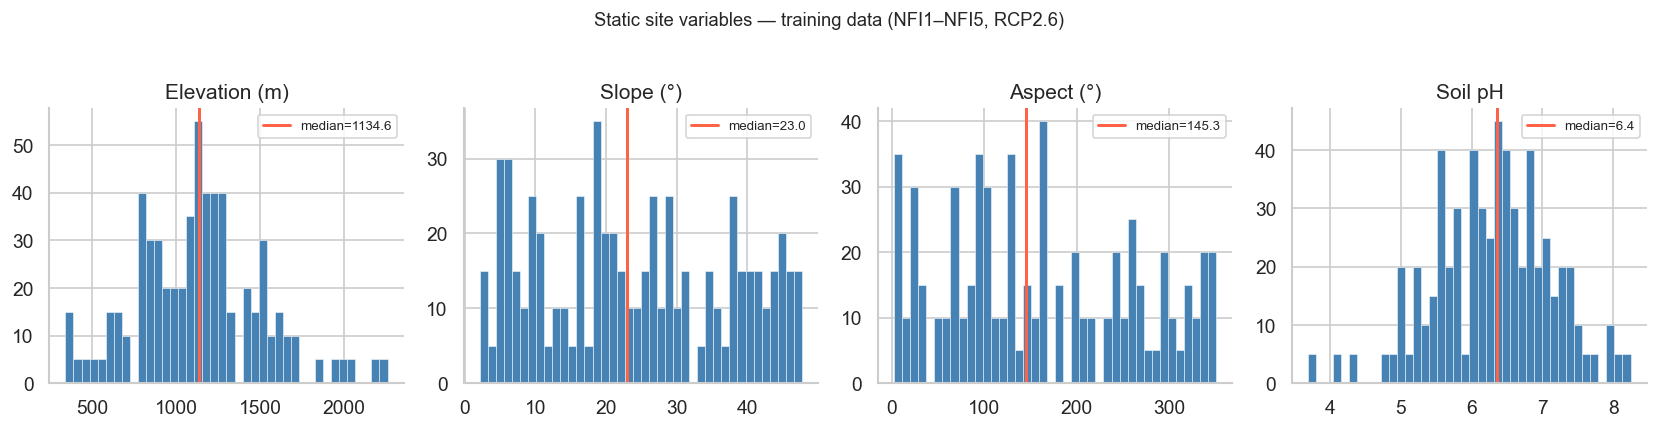

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, feat in zip(axes, STATIC_FEATURES):
    vals = train_rcp26[feat].dropna()
    ax.hist(vals, bins=40, color='steelblue', edgecolor='white', linewidth=0.3)
    ax.axvline(vals.median(), color='tomato', lw=1.8, label=f'median={vals.median():.1f}')
    ax.set_title(STATIC_LABELS[feat])
    ax.legend(fontsize=8)
    sns.despine(ax=ax)
fig.suptitle('Static site variables — training data (NFI1–NFI5, RCP2.6)', y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

### Climate feature statistics — training vs. future snapshots

In [5]:
KEY_FEATS = [
    'mean_tas_mean', 'mean_tasmax_mean', 'mean_tasmin_mean',
    'mean_pr_sum', 'mean_gdd_sum', 'mean_frost_days_count', 'mean_dry_days_count',
]

def fmt(vals):
    """min / median / max"""
    return f"{vals.min():.1f} / {vals.median():.1f} / {vals.max():.1f}"

cols_order = ['Training\n(1984–2021)']
for yr in ['~2049', '~2089']:
    for rcp in RCPS:
        cols_order.append(f'{yr}\n{RCP_LABELS[rcp]}')

table = {}
for feat in KEY_FEATS:
    row = {}
    row['Training\n(1984–2021)'] = fmt(train_rcp26[feat].dropna())
    for invnr, yr in [(850, '~2049'), (1250, '~2089')]:
        for rcp in RCPS:
            vals = df_all[(df_all['rcp'] == rcp) & (df_all['INVNR'] == invnr)][feat].dropna()
            row[f'{yr}\n{RCP_LABELS[rcp]}'] = fmt(vals)
    table[CLIMATE_LABELS[feat]] = row

coverage_table = pd.DataFrame(table).T[cols_order]
coverage_table.index.name = 'Feature'
coverage_table.columns.name = None
print('Format:  min / median / max')
coverage_table

Format:  min / median / max


,Training\n(1984–2021),~2049\nRCP 2.6,~2049\nRCP 4.5,~2049\nRCP 8.5,~2089\nRCP 2.6,~2089\nRCP 4.5,~2089\nRCP 8.5
Feature,,,,,,,
Mean temp (°C),3.1 / 8.3 / 12.3,3.4 / 8.7 / 12.5,4.0 / 9.3 / 13.1,5.3 / 10.4 / 14.1,3.9 / 9.0 / 12.9,4.6 / 9.9 / 13.6,6.6 / 11.8 / 15.5
Max temp mean (°C),7.2 / 12.5 / 16.5,7.6 / 12.8 / 16.8,8.3 / 13.5 / 17.2,9.6 / 14.6 / 18.4,8.1 / 13.2 / 17.2,8.8 / 14.1 / 17.8,11.0 / 15.9 / 19.7
Min temp mean (°C),-0.7 / 4.5 / 8.5,-0.6 / 4.9 / 8.7,0.2 / 5.5 / 9.3,1.5 / 6.7 / 10.3,0.3 / 5.2 / 9.1,0.8 / 6.1 / 9.8,2.7 / 7.9 / 11.6
Precip sum (mm),730.9 / 1010.4 / 1394.5,710.9 / 988.9 / 1282.9,675.4 / 985.3 / 1255.7,692.6 / 955.5 / 1270.6,740.3 / 998.3 / 1315.3,736.1 / 965.8 / 1265.1,666.8 / 907.1 / 1239.6
GDD sum (°C·d),878.8 / 1596.0 / 2166.5,984.2 / 1645.8 / 2090.3,1090.8 / 1709.6 / 2257.7,1176.7 / 1872.8 / 2295.9,1031.1 / 1702.5 / 2187.1,1099.3 / 1793.1 / 2255.5,1332.6 / 2030.2 / 2539.4
Frost days / yr,58.9 / 99.3 / 150.0,67.5 / 95.8 / 146.4,58.9 / 93.6 / 149.4,50.1 / 86.7 / 135.3,63.2 / 96.0 / 144.5,57.2 / 90.0 / 131.4,41.1 / 78.2 / 126.1
Dry days / yr,183.0 / 218.7 / 247.7,203.2 / 219.6 / 243.8,202.1 / 225.8 / 254.4,214.7 / 232.4 / 258.9,197.6 / 223.2 / 248.2,202.5 / 230.7 / 260.8,224.0 / 244.7 / 274.0


In [6]:
# Statistics for main-text variable table (NFI1-NFI5 training data, RCP26)
NFI_FEATS = [
    'BASFPH', 'BASFPH_squared', 'ASPECT25', 'SLOPE25', 'PH', 'Z25',
    'HWSW_prop', 'INVYR', 'Time_Diff_years', 'BEWIRTINT1', 'NAISHSTKOMB',
]
TARGET_FEATS = ['BASFPH_next_INVNR', 'HWSW_prop_next_INVNR']
ALL_FEATS = NFI_FEATS + CLIMATE_FEATURES + TARGET_FEATS

rows = []
for feat in ALL_FEATS:
    if feat in train_rcp26.columns:
        v = train_rcp26[feat].dropna()
        rows.append({
            'Feature': feat,
            'Median': v.median(),
            'Q25': v.quantile(0.25),
            'Q75': v.quantile(0.75),
            'N': len(v),
        })
    else:
        print(f'WARNING: {feat} not found')

stats_df = pd.DataFrame(rows).set_index('Feature').round(3)
stats_df


,Median,Q25,Q75,N
Feature,,,,
BASFPH,32.669,25.199,40.331,600
BASFPH_squared,1067.235,634.985,1626.574,600
ASPECT25,145.329,80.346,254.355,600
SLOPE25,22.981,11.490,36.302,600
PH,6.358,5.682,6.853,600
Z25,1134.588,869.974,1333.869,600
HWSW_prop,0.555,0.323,0.699,600
INVYR,2005.000,1994.000,2012.000,600
Time_Diff_years,10.000,10.000,10.000,600


## 2 · Climate Variable Trends Over Time

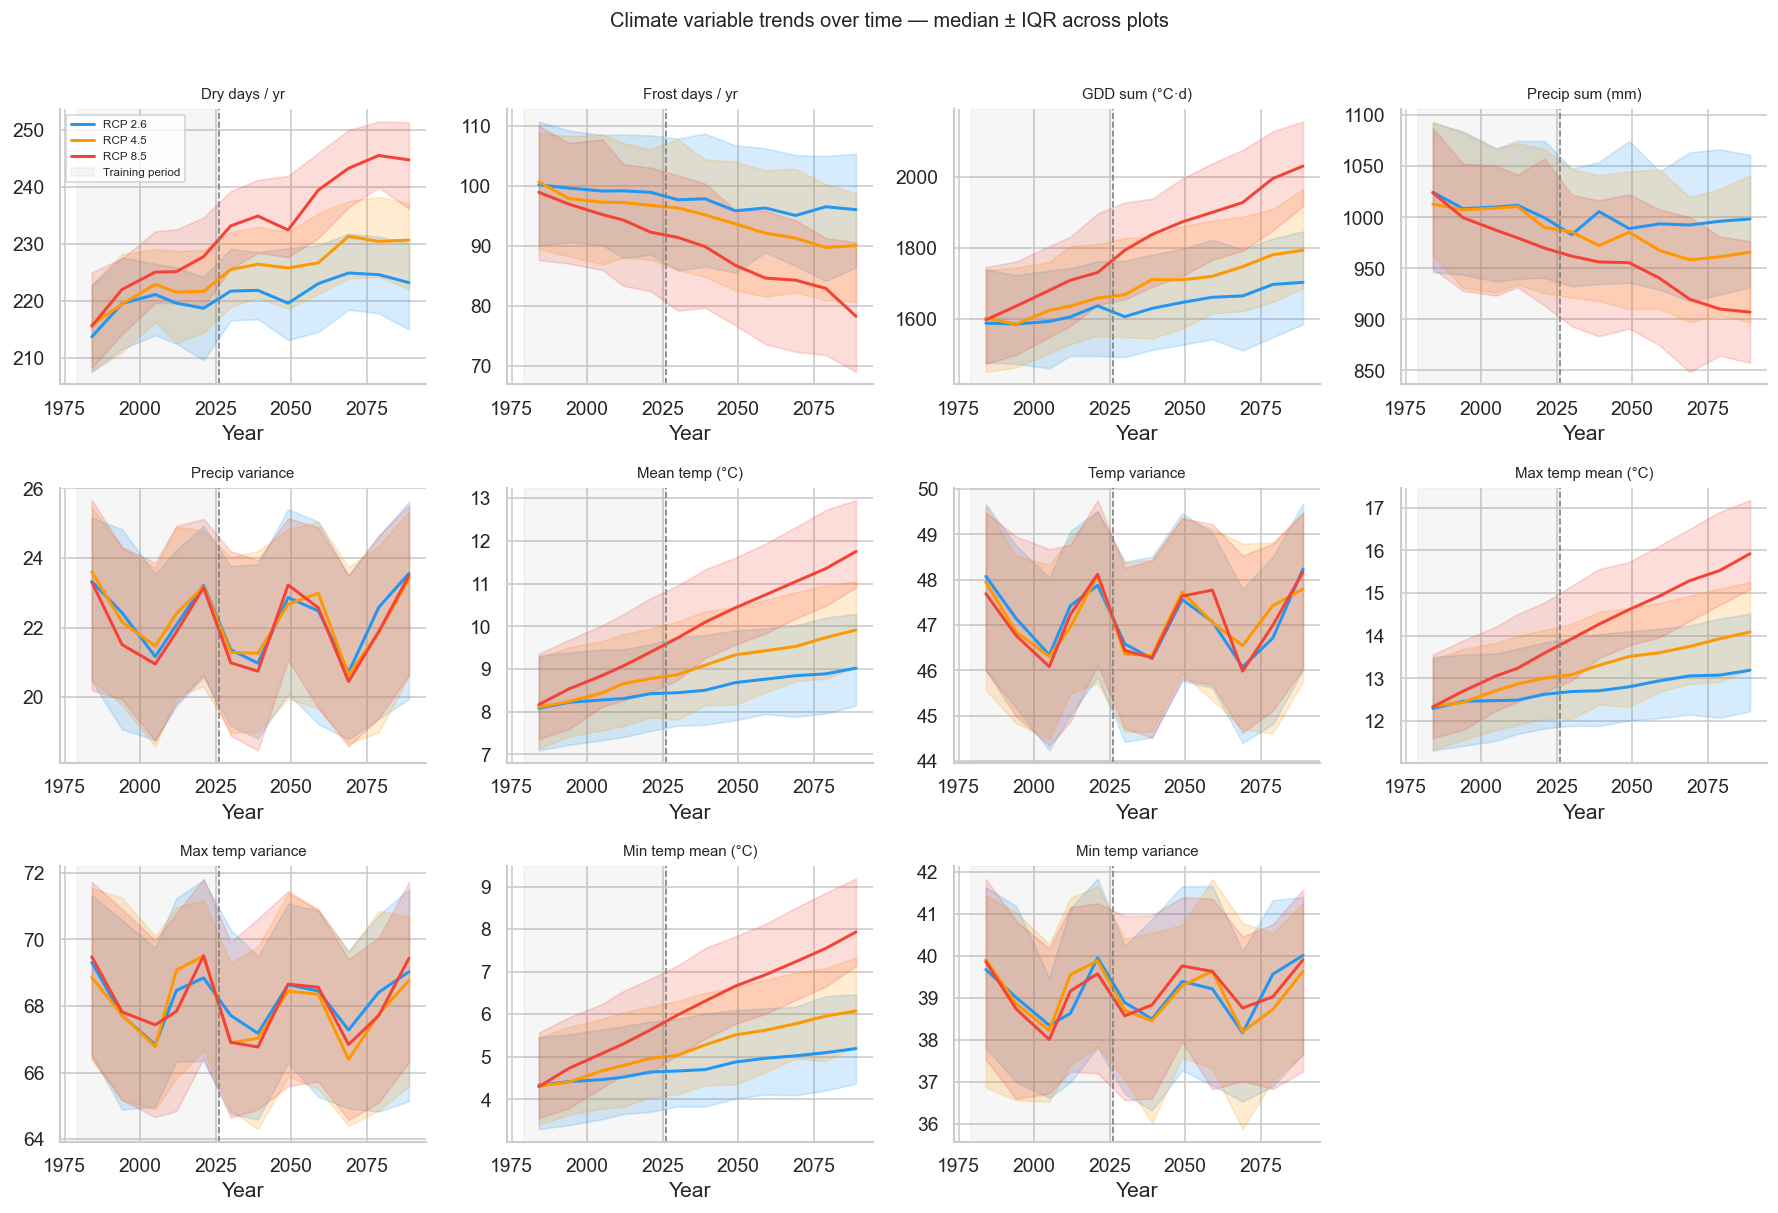

In [7]:
def climate_trend_figure(feature, ax, df_combined, show_legend=True):
    for rcp in RCPS:
        sub = df_combined[df_combined['rcp'] == rcp]
        stats = sub.groupby('INVNR')[feature].agg(['median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
        stats.columns = ['median', 'q25', 'q75']
        years = [INVNR_YEAR[i] for i in stats.index]
        c = RCP_COLORS[rcp]
        ax.plot(years, stats['median'], color=c, lw=1.8, label=RCP_LABELS[rcp])
        ax.fill_between(years, stats['q25'], stats['q75'], alpha=0.18, color=c)
    train_years = [INVNR_YEAR[i] for i in TRAINING_INVNRS]
    ax.axvspan(min(train_years) - 5, max(train_years) + 5, alpha=0.07, color='grey', label='Training period')
    ax.axvline(INVNR_YEAR[550] + 5, color='grey', lw=1, ls='--')
    ax.set_title(CLIMATE_LABELS[feature], fontsize=9)
    ax.set_xlabel('Year')
    if show_legend:
        ax.legend(fontsize=7, loc='upper left')
    sns.despine(ax=ax)

df_plot = df_all[df_all['INVNR'].isin(ALL_INVNRS)].dropna(subset=['mean_tas_mean'])

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes_flat = axes.flatten()
for i, feat in enumerate(CLIMATE_FEATURES):
    climate_trend_figure(feat, axes_flat[i], df_plot, show_legend=(i == 0))
axes_flat[-1].set_visible(False)
fig.suptitle('Climate variable trends over time — median ± IQR across plots', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 3 · Per-Feature Range Analysis (Univariate)

In [8]:
# Training range statistics — used by both §3 and §4
train_stats = {}
for feat in CLIMATE_FEATURES:
    vals = train_rcp26[feat].dropna()
    train_stats[feat] = {'min': vals.min(), 'max': vals.max()}

records = []
for rcp in RCPS:
    for invnr in FUTURE_INVNRS:
        sub = df_all[(df_all['rcp'] == rcp) & (df_all['INVNR'] == invnr)].dropna(subset=['mean_tas_mean'])
        if len(sub) == 0:
            continue
        for feat in CLIMATE_FEATURES:
            vals = sub[feat].dropna()
            lo, hi = train_stats[feat]['min'], train_stats[feat]['max']
            records.append({
                'rcp': rcp, 'invnr': invnr, 'year': INVNR_YEAR[invnr],
                'feature': feat, 'label': CLIMATE_LABELS[feat],
                'frac_outside': ((vals < lo) | (vals > hi)).mean()
            })

exceedance_df = pd.DataFrame(records)
print(f'Computed exceedance for {len(exceedance_df)} (INVNR × RCP × feature) combinations')

Computed exceedance for 231 (INVNR × RCP × feature) combinations


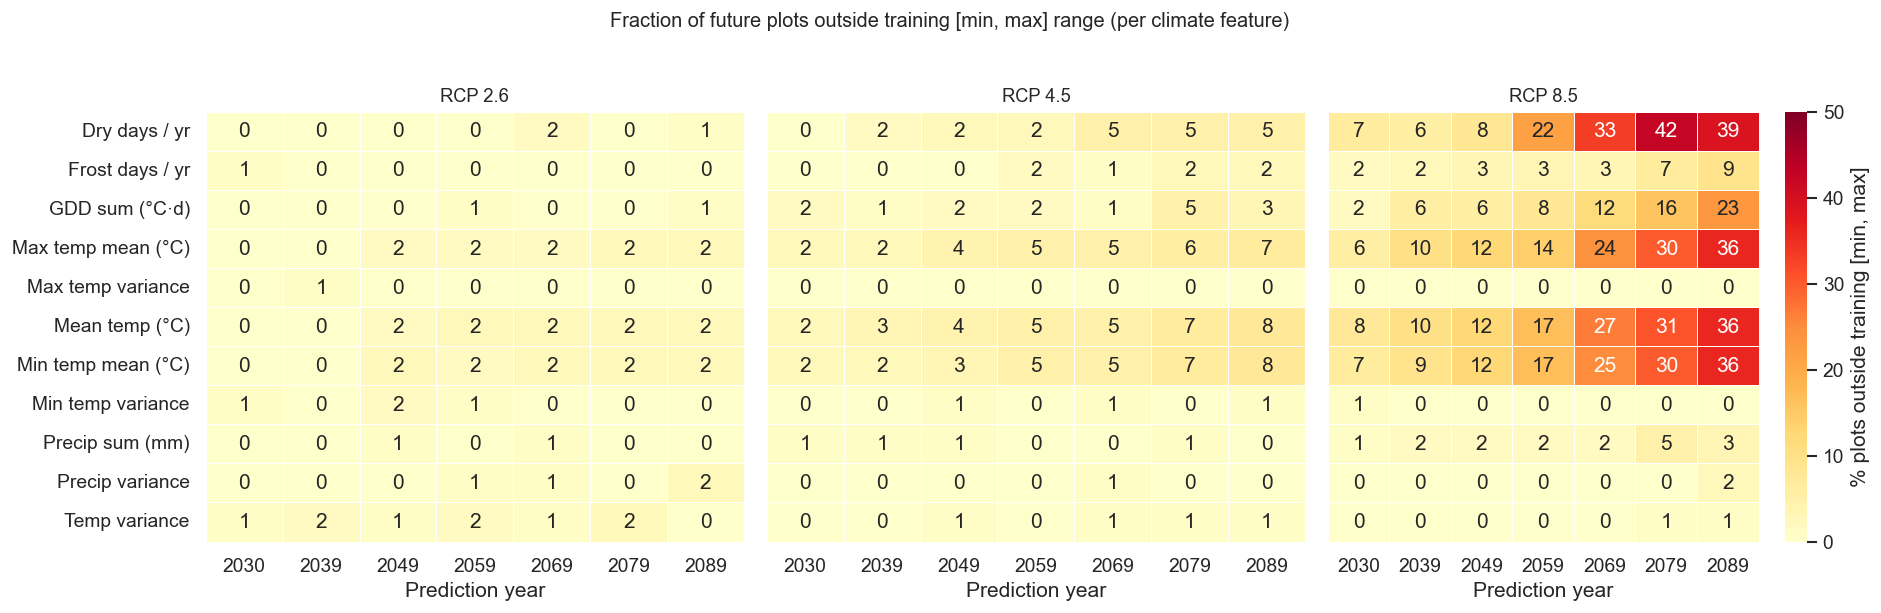

In [9]:
# Heatmap: fraction of plots outside training [min, max] per feature × year
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, rcp in zip(axes, RCPS):
    pivot = exceedance_df[exceedance_df['rcp'] == rcp].pivot(
        index='label', columns='year', values='frac_outside'
    )
    sns.heatmap(
        pivot * 100, ax=ax, cmap='YlOrRd', vmin=0, vmax=50,
        annot=True, fmt='.0f', linewidths=0.5,
        cbar=(rcp == 'RCP85'), cbar_kws={'label': '% plots outside training [min, max]'}
    )
    ax.set_title(RCP_LABELS[rcp], fontsize=11)
    ax.set_xlabel('Prediction year')
    ax.set_ylabel('')
fig.suptitle('Fraction of future plots outside training [min, max] range (per climate feature)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

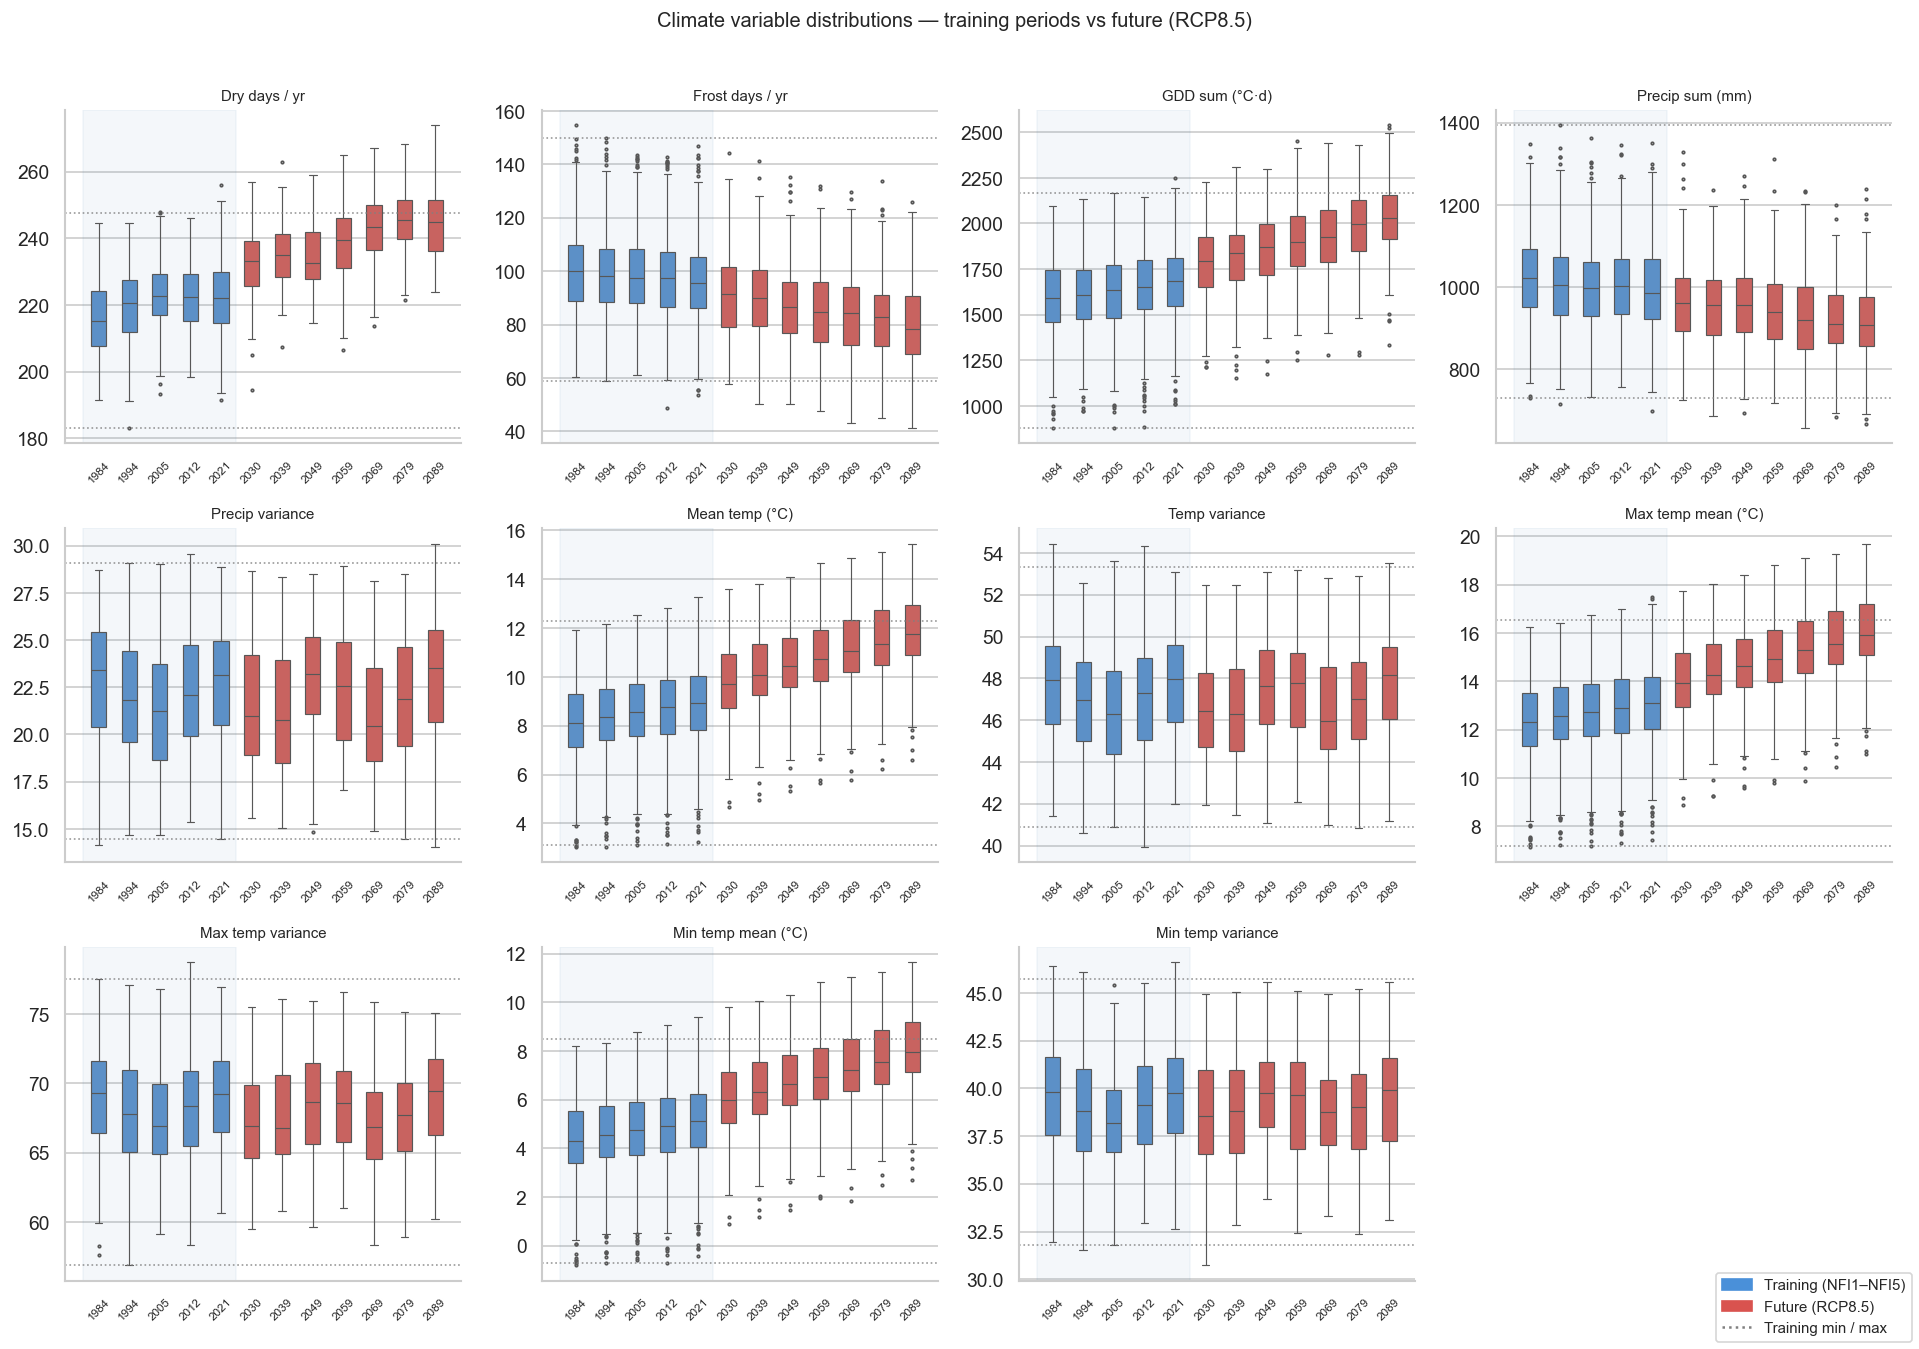

In [10]:
# Box plots: training periods vs future under RCP8.5, with training [min, max] lines
df_box = df_all[
    (df_all['INVNR'].isin(ALL_INVNRS)) &
    (df_all['mean_tas_mean'].notna()) &
    ((df_all['rcp'] == 'RCP85') | (df_all['INVNR'].isin(TRAINING_INVNRS)))
].copy()
df_box['period'] = df_box['INVNR'].map(INVNR_YEAR).astype(str)
df_box['type']   = df_box['INVNR'].apply(lambda x: 'Training' if x in TRAINING_INVNRS else 'Future (RCP8.5)')

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes_flat = axes.flatten()
for i, feat in enumerate(CLIMATE_FEATURES):
    ax = axes_flat[i]
    sns.boxplot(
        data=df_box, x='period', y=feat, ax=ax,
        hue='type', palette={'Training': '#4a90d9', 'Future (RCP8.5)': '#d9534f'},
        dodge=False, width=0.5, linewidth=0.7, fliersize=1.5,
        order=[str(INVNR_YEAR[j]) for j in ALL_INVNRS]
    )
    ax.axhline(train_stats[feat]['min'], color='grey', lw=1, ls=':', alpha=0.8)
    ax.axhline(train_stats[feat]['max'], color='grey', lw=1, ls=':', alpha=0.8)
    ax.axvspan(-0.5, len(TRAINING_INVNRS) - 0.5, alpha=0.06, color='steelblue')
    ax.set_title(CLIMATE_LABELS[feat], fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.get_legend().remove()
    sns.despine(ax=ax)
axes_flat[-1].set_visible(False)
handles = [
    mpatches.Patch(color='#4a90d9', label='Training (NFI1–NFI5)'),
    mpatches.Patch(color='#d9534f', label='Future (RCP8.5)'),
    plt.Line2D([0], [0], color='grey', ls=':', label='Training min / max'),
]
fig.legend(handles=handles, loc='lower right', fontsize=9, frameon=True)
fig.suptitle('Climate variable distributions — training periods vs future (RCP8.5)', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 4 · Bounding-Box Hull Analysis

A plot at a given future time step is classified as **outside the training hull** if **any** of its 11 climate features falls outside the training `[min, max]` range.

This is the axis-aligned bounding box of the training data in climate feature space — the most direct definition of "the model encounters a value it never saw during training".

In [11]:
# For each (future INVNR, RCP): which plots are outside and which feature(s) push them out
hull_records = []
for rcp in RCPS:
    for invnr in FUTURE_INVNRS:
        sub = df_all[(df_all['rcp'] == rcp) & (df_all['INVNR'] == invnr)][CLIMATE_FEATURES + ['CLNR']].dropna(subset=CLIMATE_FEATURES).copy()
        if len(sub) == 0:
            continue
        outside_any = pd.Series(False, index=sub.index)
        per_feat_outside = {}
        for feat in CLIMATE_FEATURES:
            lo, hi = train_stats[feat]['min'], train_stats[feat]['max']
            feat_out = (sub[feat] < lo) | (sub[feat] > hi)
            outside_any = outside_any | feat_out
            per_feat_outside[feat] = feat_out.mean()
        hull_records.append({
            'rcp': rcp, 'invnr': invnr, 'year': INVNR_YEAR[invnr],
            'n_plots': len(sub),
            'n_outside': int(outside_any.sum()),
            'frac_outside': outside_any.mean(),
            'clnr_outside': sub.loc[outside_any, 'CLNR'].values.tolist(),
            **{f'frac_{feat}': per_feat_outside[feat] for feat in CLIMATE_FEATURES}
        })

hull_df = pd.DataFrame(hull_records)
print(hull_df[['rcp', 'year', 'n_plots', 'n_outside', 'frac_outside']].to_string(index=False))

  rcp  year  n_plots  n_outside  frac_outside
RCP26  2030      120          3      0.025000
RCP26  2039      120          3      0.025000
RCP26  2049      120          6      0.050000
RCP26  2059      120          7      0.058333
RCP26  2069      120          7      0.058333
RCP26  2079      120          6      0.050000
RCP26  2089      120          6      0.050000
RCP45  2030      120          4      0.033333
RCP45  2039      120          4      0.033333
RCP45  2049      120          9      0.075000
RCP45  2059      120          8      0.066667
RCP45  2069      120         13      0.108333
RCP45  2079      120         12      0.100000
RCP45  2089      120         13      0.108333
RCP85  2030      120         15      0.125000
RCP85  2039      120         16      0.133333
RCP85  2049      120         20      0.166667
RCP85  2059      120         34      0.283333
RCP85  2069      120         50      0.416667
RCP85  2079      120         61      0.508333
RCP85  2089      120         63   

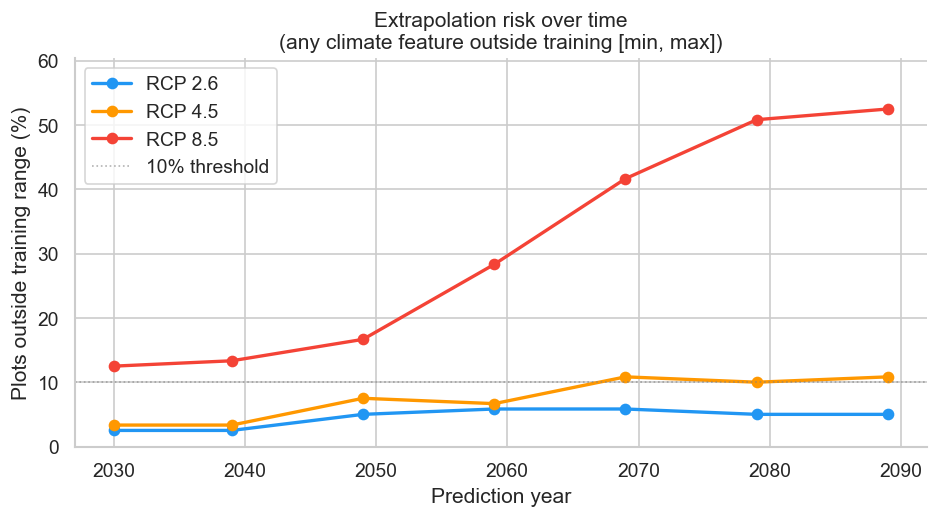

In [12]:
# Line plot: fraction outside hull over time, per RCP
fig, ax = plt.subplots(figsize=(8, 4.5))
for rcp in RCPS:
    sub = hull_df[hull_df['rcp'] == rcp].sort_values('year')
    ax.plot(sub['year'], sub['frac_outside'] * 100,
            'o-', color=RCP_COLORS[rcp], lw=2, ms=6, label=RCP_LABELS[rcp])
ax.axhline(10, color='grey', ls=':', lw=1, alpha=0.6, label='10% threshold')
ax.set_xlabel('Prediction year')
ax.set_ylabel('Plots outside training range (%)')
ax.set_title('Extrapolation risk over time\n(any climate feature outside training [min, max])')
ax.legend()
ax.set_ylim(0, max(hull_df['frac_outside'].max() * 100 * 1.15, 15))
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

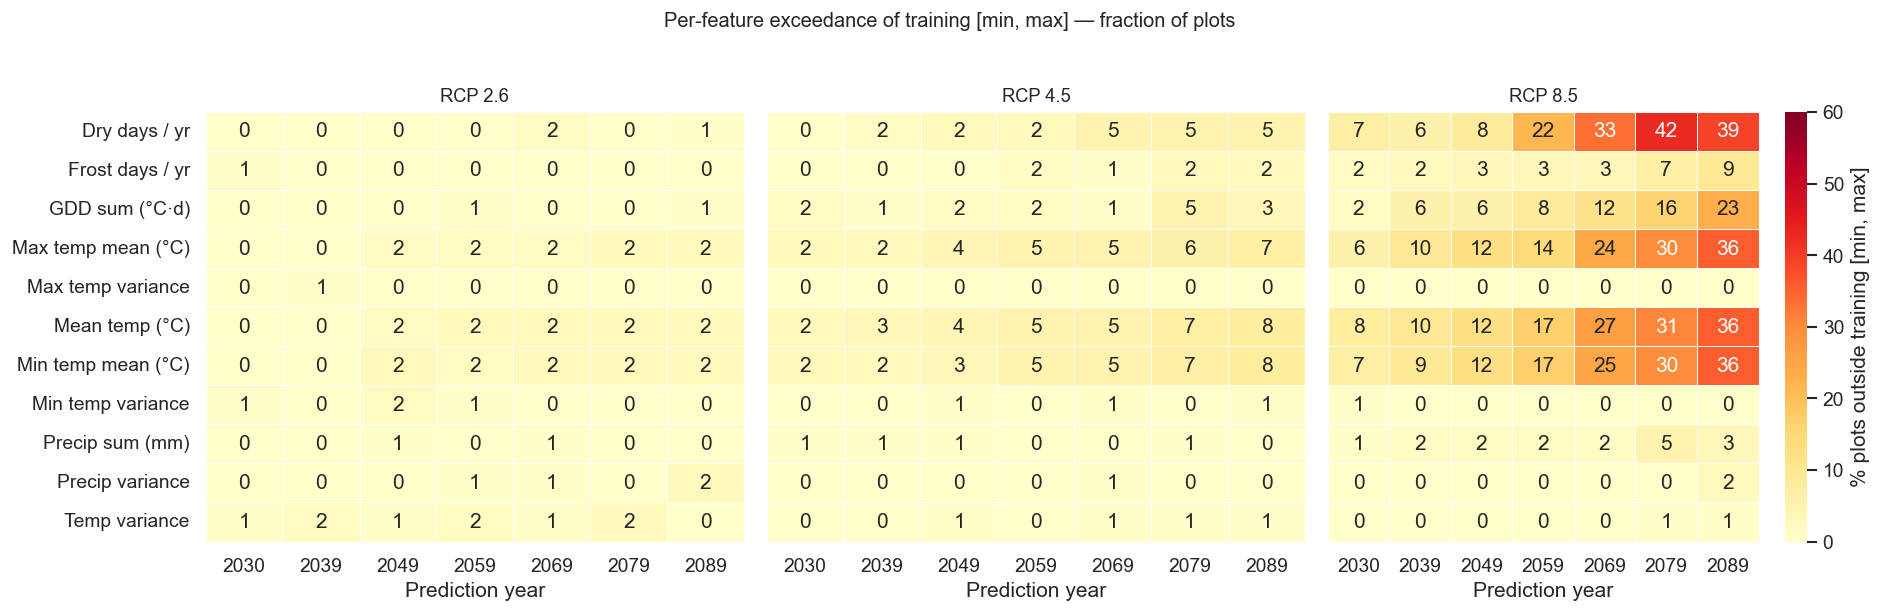

In [13]:
# Per-feature contribution: which feature is responsible for pushing plots outside?
# For each (RCP, year): fraction of plots where each feature individually is out of range
feat_contrib_records = []
for _, row in hull_df.iterrows():
    for feat in CLIMATE_FEATURES:
        feat_contrib_records.append({
            'rcp': row['rcp'], 'year': row['year'],
            'label': CLIMATE_LABELS[feat],
            'frac_this_feat': row[f'frac_{feat}']
        })
feat_contrib_df = pd.DataFrame(feat_contrib_records)

# Heatmap: per-feature fraction outside training [min,max] — one panel per RCP
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, rcp in zip(axes, RCPS):
    pivot = feat_contrib_df[feat_contrib_df['rcp'] == rcp].pivot(
        index='label', columns='year', values='frac_this_feat'
    )
    sns.heatmap(
        pivot * 100, ax=ax, cmap='YlOrRd', vmin=0, vmax=60,
        annot=True, fmt='.0f', linewidths=0.5,
        cbar=(rcp == 'RCP85'), cbar_kws={'label': '% plots outside training [min, max]'}
    )
    ax.set_title(RCP_LABELS[rcp], fontsize=11)
    ax.set_xlabel('Prediction year')
    ax.set_ylabel('')
fig.suptitle('Per-feature exceedance of training [min, max] — fraction of plots', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 5 · Spatial Distribution of Extrapolation Risk

In [14]:
# For each (plot, RCP): count how many of the 7 future steps are outside the bounding-box hull
plot_outside_count = {}
for rcp in RCPS:
    for invnr in FUTURE_INVNRS:
        sub = df_all[(df_all['rcp'] == rcp) & (df_all['INVNR'] == invnr)][CLIMATE_FEATURES + ['CLNR']].dropna(subset=CLIMATE_FEATURES)
        if len(sub) == 0:
            continue
        outside_any = pd.Series(False, index=sub.index)
        for feat in CLIMATE_FEATURES:
            lo, hi = train_stats[feat]['min'], train_stats[feat]['max']
            outside_any = outside_any | ((sub[feat] < lo) | (sub[feat] > hi))
        for clnr, is_out in zip(sub['CLNR'].values, outside_any.values):
            key = (clnr, rcp)
            plot_outside_count[key] = plot_outside_count.get(key, 0) + (1 if is_out else 0)

coord_map = train_rcp26.groupby('CLNR')[['X', 'Y']].first().reset_index()
map_rows = []
for rcp in RCPS:
    for _, row in coord_map.iterrows():
        count = plot_outside_count.get((row['CLNR'], rcp), 0)
        map_rows.append({'CLNR': row['CLNR'], 'X': row['X'], 'Y': row['Y'],
                          'rcp': rcp, 'n_steps_outside': count,
                          'frac_steps_outside': count / len(FUTURE_INVNRS)})
map_df = pd.DataFrame(map_rows)
print(f'Spatial map: {map_df["CLNR"].nunique()} plots × 3 RCPs')

Spatial map: 120 plots × 3 RCPs


In [15]:
try:
    ch_border = gpd.read_file(SHP_PATH).to_crs('EPSG:21781')
    has_border = True
    print('Switzerland boundary loaded.')
except Exception as e:
    has_border = False
    print(f'Could not load border: {e}')

Could not load border: ../../data/raw/map_data/swissboundaries3d_2025-04_2056_5728.shp/swissBOUNDARIES3D_1_5_TLM_LANDESGEBIET.shp: No such file or directory


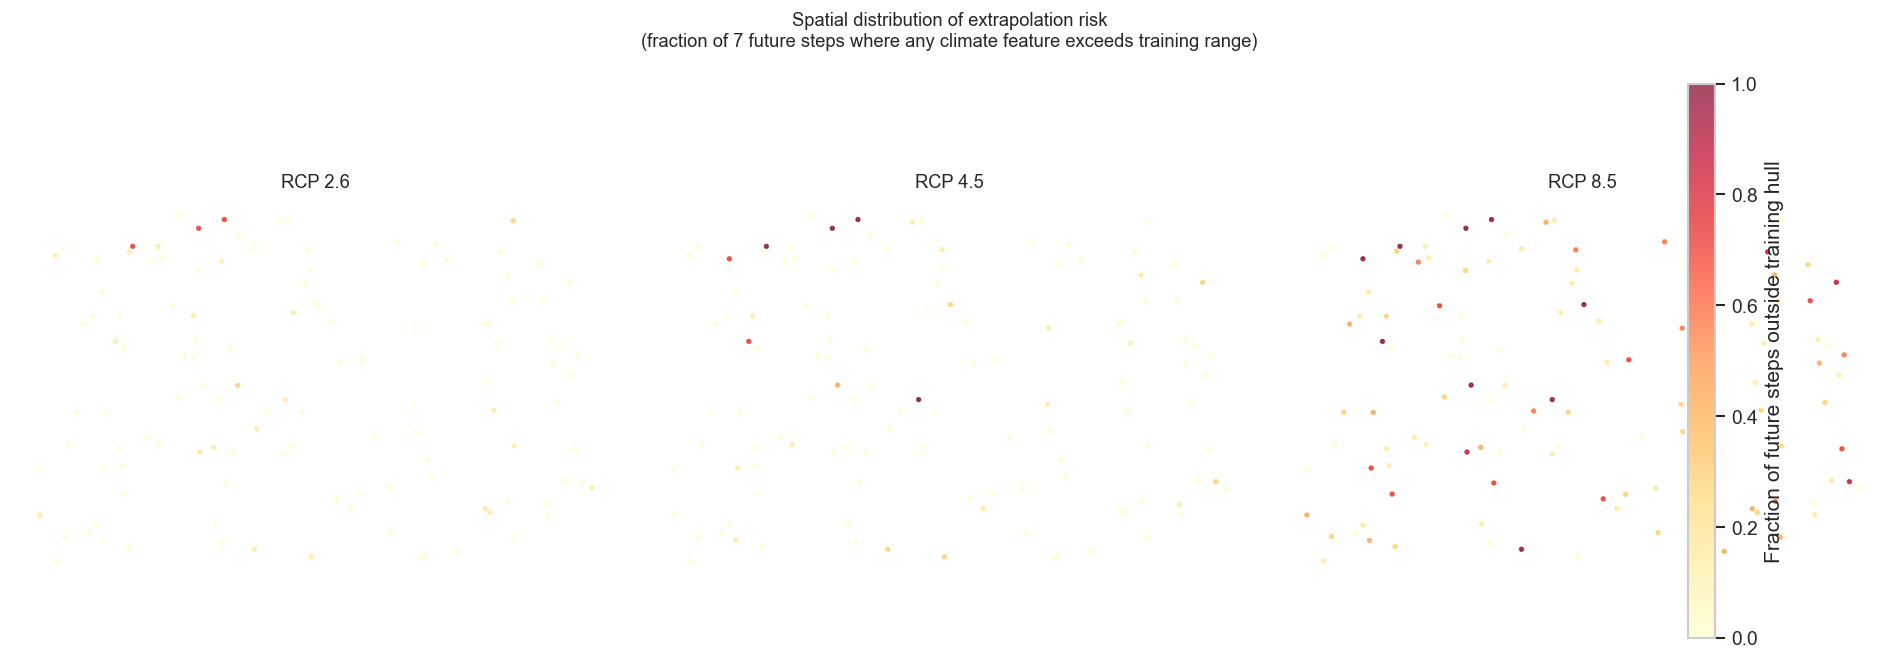

In [16]:
# Map: fraction of future steps outside hull per plot, one panel per RCP
worst_case = map_df.groupby('CLNR').agg(
    X=('X', 'first'), Y=('Y', 'first'), max_frac=('frac_steps_outside', 'max')
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, rcp in zip(axes, RCPS):
    sub = map_df[map_df['rcp'] == rcp]
    if has_border:
        ch_border.plot(ax=ax, color='none', edgecolor='#444', linewidth=0.6)
    sc = ax.scatter(sub['X'], sub['Y'], c=sub['frac_steps_outside'],
                    cmap='YlOrRd', vmin=0, vmax=1, s=5, alpha=0.7, rasterized=True)
    ax.set_title(RCP_LABELS[rcp], fontsize=11)
    ax.set_aspect('equal')
    ax.axis('off')
cbar = fig.colorbar(sc, ax=axes, orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label('Fraction of future steps outside training hull')
fig.suptitle('Spatial distribution of extrapolation risk\n(fraction of 7 future steps where any climate feature exceeds training range)', fontsize=11)
plt.tight_layout()
plt.show()

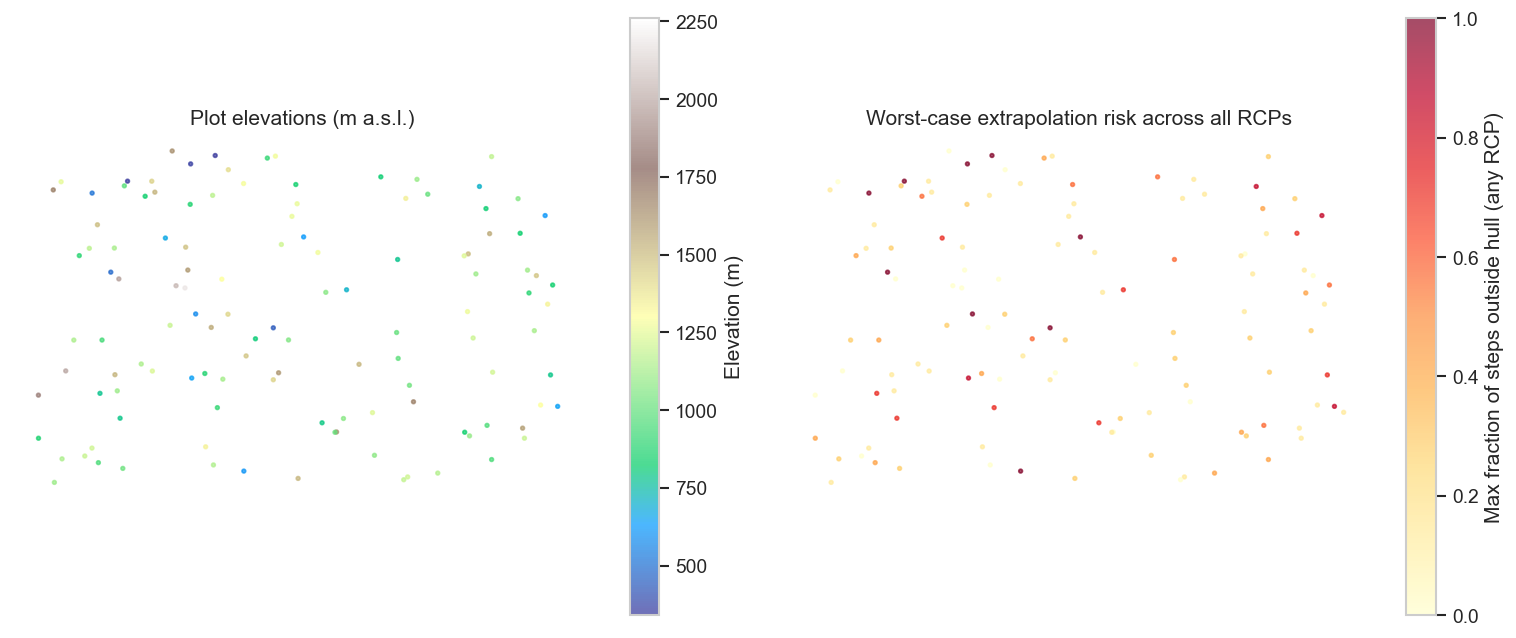

In [17]:
# Elevation context alongside worst-case risk map
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
elev_data = train_rcp26.groupby('CLNR')[['X', 'Y', 'Z25']].first().reset_index()

ax = axes[0]
if has_border:
    ch_border.plot(ax=ax, color='none', edgecolor='#444', linewidth=0.6)
sc_e = ax.scatter(elev_data['X'], elev_data['Y'], c=elev_data['Z25'],
                  cmap='terrain', s=5, alpha=0.7, rasterized=True)
plt.colorbar(sc_e, ax=ax, label='Elevation (m)')
ax.set_title('Plot elevations (m a.s.l.)')
ax.set_aspect('equal')
ax.axis('off')

ax2 = axes[1]
if has_border:
    ch_border.plot(ax=ax2, color='none', edgecolor='#444', linewidth=0.6)
merged_elev = worst_case.merge(elev_data[['CLNR', 'Z25']], on='CLNR')
sc2 = ax2.scatter(merged_elev['X'], merged_elev['Y'], c=merged_elev['max_frac'],
                   cmap='YlOrRd', vmin=0, vmax=1, s=5, alpha=0.7, rasterized=True)
plt.colorbar(sc2, ax=ax2, label='Max fraction of steps outside hull (any RCP)')
ax2.set_title('Worst-case extrapolation risk across all RCPs')
ax2.set_aspect('equal')
ax2.axis('off')

plt.tight_layout()
plt.show()

## 6 · Summary & Interpretation

In [18]:
summary_pivot = hull_df.pivot(index='year', columns='rcp', values='frac_outside') * 100
summary_pivot.columns = [RCP_LABELS[c] for c in summary_pivot.columns]
summary_pivot.index.name = 'Prediction year'
print('Fraction of plots outside training bounding-box hull (%)')
summary_pivot.round(1)

Fraction of plots outside training bounding-box hull (%)


,RCP 2.6,RCP 4.5,RCP 8.5
Prediction year,,,
2030,2.5,3.3,12.5
2039,2.5,3.3,13.3
2049,5.0,7.5,16.7
2059,5.8,6.7,28.3
2069,5.8,10.8,41.7
2079,5.0,10.0,50.8
2089,5.0,10.8,52.5


In [19]:
worst_rcp      = hull_df.loc[hull_df['frac_outside'].idxmax()]
first_exceed10 = hull_df[hull_df['frac_outside'] >= 0.10].sort_values('year')
last_rcp85     = exceedance_df[(exceedance_df['rcp'] == 'RCP85') & (exceedance_df['invnr'] == 1250)].sort_values('frac_outside', ascending=False)

print('=== Key findings ===')
print(f'\nMaximum hull exceedance: {worst_rcp["frac_outside"]*100:.1f}% of plots'
      f' at year {worst_rcp["year"]} under {RCP_LABELS[worst_rcp["rcp"]]}')
if len(first_exceed10) > 0:
    fe = first_exceed10.iloc[0]
    print(f'First year >10% of plots outside hull: {fe["year"]} under {RCP_LABELS[fe["rcp"]]}')
else:
    print('Hull exceedance never exceeds 10% of plots across any scenario.')

print(f'\nTop 5 per-feature drivers of exceedance (RCP8.5, ~2089):')
for _, r in last_rcp85.head(5).iterrows():
    print(f'  {r["label"]}: {r["frac_outside"]*100:.1f}% of plots outside training [min, max]')

=== Key findings ===

Maximum hull exceedance: 52.5% of plots at year 2089 under RCP 8.5
First year >10% of plots outside hull: 2030 under RCP 8.5

Top 5 per-feature drivers of exceedance (RCP8.5, ~2089):
  Dry days / yr: 39.2% of plots outside training [min, max]
  Mean temp (°C): 35.8% of plots outside training [min, max]
  Max temp mean (°C): 35.8% of plots outside training [min, max]
  Min temp mean (°C): 35.8% of plots outside training [min, max]
  GDD sum (°C·d): 23.3% of plots outside training [min, max]


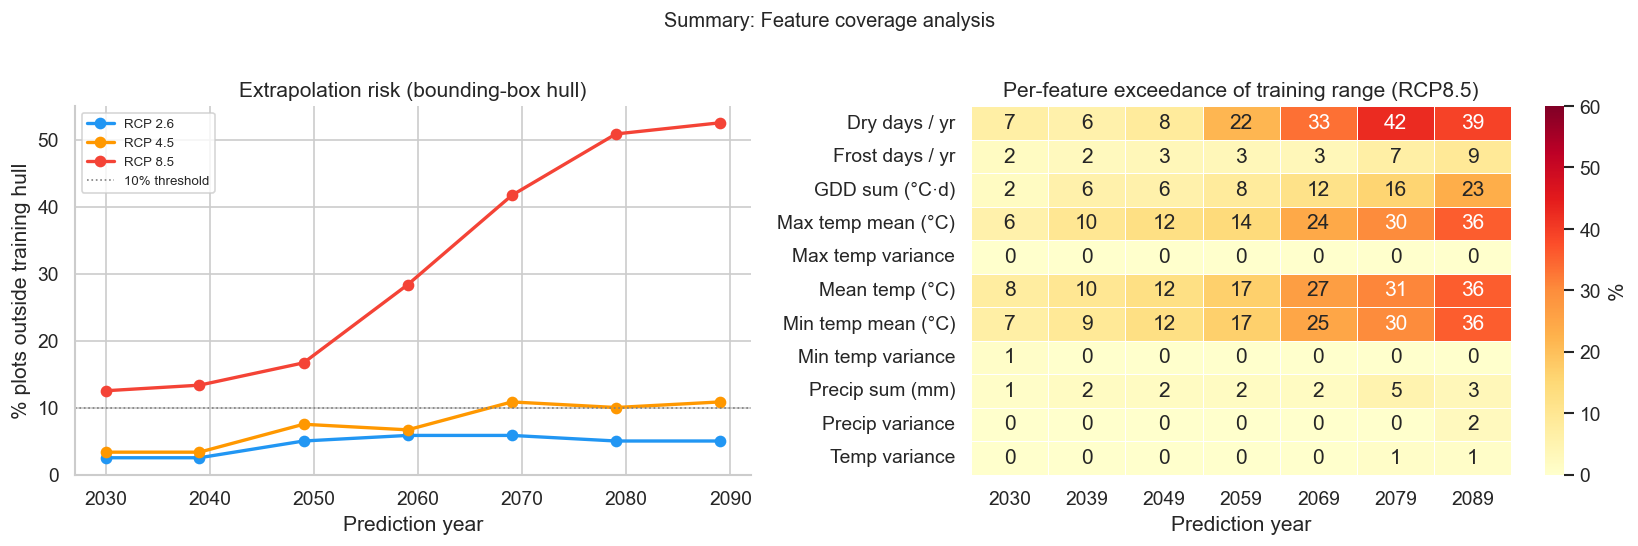

In [20]:
# Combined summary figure
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax1 = axes[0]
for rcp in RCPS:
    sub = hull_df[hull_df['rcp'] == rcp].sort_values('year')
    ax1.plot(sub['year'], sub['frac_outside'] * 100,
             'o-', color=RCP_COLORS[rcp], lw=2, ms=6, label=RCP_LABELS[rcp])
ax1.axhline(10, color='grey', ls=':', lw=1, label='10% threshold')
ax1.set_xlabel('Prediction year')
ax1.set_ylabel('% plots outside training hull')
ax1.set_title('Extrapolation risk (bounding-box hull)')
ax1.legend(fontsize=8)
sns.despine(ax=ax1)

ax2 = axes[1]
rcp85_pivot = feat_contrib_df[feat_contrib_df['rcp'] == 'RCP85'].pivot(
    index='label', columns='year', values='frac_this_feat'
) * 100
sns.heatmap(rcp85_pivot, ax=ax2, cmap='YlOrRd', vmin=0, vmax=60,
            annot=True, fmt='.0f', linewidths=0.5, cbar_kws={'label': '%'})
ax2.set_title('Per-feature exceedance of training range (RCP8.5)')
ax2.set_xlabel('Prediction year')
ax2.set_ylabel('')

fig.suptitle('Summary: Feature coverage analysis', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()